In [20]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
!wget $data

--2026-10-16 16:41:40--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8001::154, 2606:50c0:8002::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8001::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1475504 (1.4M) [text/plain]
Saving to: ‘data.csv.4’

data.csv.4          100%[===================>]   1.41M  8.52MB/s    in 0.2s    

2026-10-16 16:41:41 (8.52 MB/s) - ‘data.csv.4’ saved [1475504/1475504]



In [21]:
import pandas as pd

df = pd.read_csv('data.csv')

In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  str    
 1   Model              11914 non-null  str    
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  str    
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  str    
 7   Driven_Wheels      11914 non-null  str    
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   str    
 10  Vehicle Size       11914 non-null  str    
 11  Vehicle Style      11914 non-null  str    
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5), str(8)
m

In [23]:
df.columns.str.lower()

Index(['make', 'model', 'year', 'engine fuel type', 'engine hp',
       'engine cylinders', 'transmission type', 'driven_wheels',
       'number of doors', 'market category', 'vehicle size', 'vehicle style',
       'highway mpg', 'city mpg', 'popularity', 'msrp'],
      dtype='str')

In [24]:
df.columns.str.lower().str.replace(' ', '_')

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

In [25]:
df.dtypes

Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Market Category          str
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

In [26]:
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

[]

In [27]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [28]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

Make
<StringArray>
['BMW', 'Audi', 'FIAT', 'Mercedes-Benz', 'Chrysler']
Length: 5, dtype: str
48

Model
<StringArray>
['1 Series M', '1 Series', '100', '124 Spider', '190-Class']
Length: 5, dtype: str
915

Year
[2011 2012 2013 1992 1993]
28

Engine Fuel Type
<StringArray>
[   'premium unleaded (required)',               'regular unleaded',
 'premium unleaded (recommended)',       'flex-fuel (unleaded/E85)',
                         'diesel']
Length: 5, dtype: str
10

Engine HP
[335. 300. 230. 320. 172.]
356

Engine Cylinders
[ 6.  4.  5.  8. 12.]
9

Transmission Type
<StringArray>
['MANUAL', 'AUTOMATIC', 'AUTOMATED_MANUAL', 'DIRECT_DRIVE', 'UNKNOWN']
Length: 5, dtype: str
5

Driven_Wheels
<StringArray>
['rear wheel drive', 'front wheel drive', 'all wheel drive',
 'four wheel drive']
Length: 4, dtype: str
4

Number of Doors
[ 2.  4.  3. nan]
3

Market Category
<StringArray>
['Factory Tuner,Luxury,High-Performance',
                    'Luxury,Performance',
               'Luxury,High-Pe

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


# Distribution of price


The price column deserves a closer look. Looking at numbers is not very informative — we don't see the big picture. So we visualize it. For plotting we use two libraries: matplotlib, which is a low-level plotting library, and seaborn, a library on top of it that makes things easier. The %matplotlib inline line makes sure the plots are displayed in the notebook:



<Axes: xlabel='MSRP', ylabel='Count'>

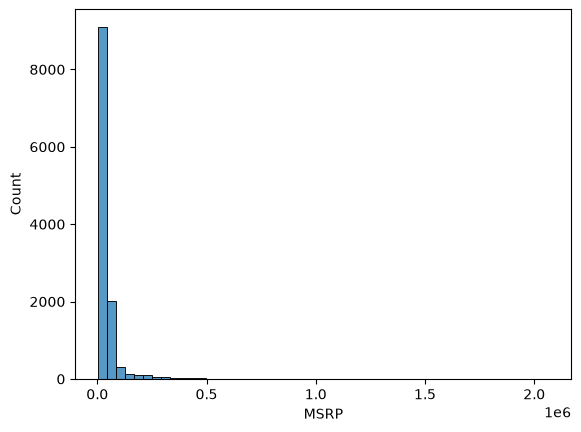

In [31]:
sns.histplot(df.MSRP, bins=50)

<Axes: xlabel='MSRP', ylabel='Count'>

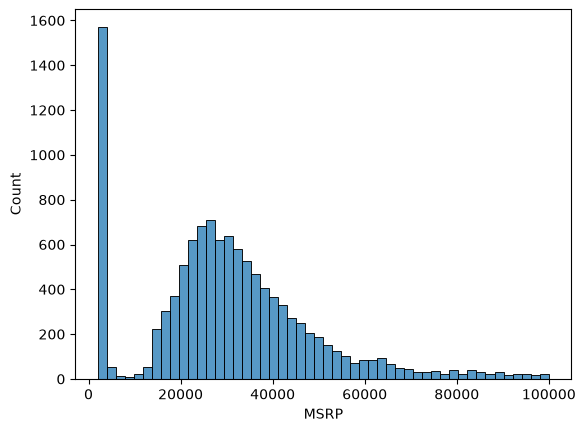

In [32]:
sns.histplot(df.MSRP[df.MSRP < 100000], bins=50)

The 1e6 on the x axis is scientific notation: 10 to the power of 6, that is, one million. And what we see is that a lot of prices are pretty cheap — most of the cars are concentrated on the left. Then there are very few cars that are super expensive: maybe one car costs 2 million, one costs 1.5 million, and a few cost around a million. There are not so many of them, but they have huge values.

This kind of distribution is called a long-tail distribution: most of the data sits in one place, and a shallow tail stretches far to the right. Long-tail distributions are very common for prices: most things are cheap because that's what the general public can afford, but there are a few super-expensive items for the few people who can buy them.

To see the shape better, we zoom in on prices below 100,000:

# Removing the long tail with a logarithm

While this distribution is not unexpected, it is not really good for machine learning: the long tail will confuse the model and screw things up. We want to get rid of it, and the usual trick is to apply the logarithm to the price.

The logarithm compresses large values. For large numbers, the value of the logarithm is not that large: going from 10 to 1,000 is a big jump, but the increase between their logarithms is not that high. So the logarithm takes very high values and makes them lower.

There is one problem with the plain logarithm: the logarithm of zero doesn't exist. If there is a zero in the data, numpy complains — it returns negative infinity and prints a warning:

In [33]:
import numpy as np

In [34]:
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [ ]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])